# Notebook 25: Geoquímica Multielemental Continua y Reentrenamiento Nacional

## 1. Fundamento Geocientífico: La Geoquímica como Vector Universal del Sistema Mineral
En los cuadernos anteriores (NB 20 a NB 24), el modelo nacional experimentó un estancamiento en la generalización ciega (*out-of-fold*, ~35-40% en Top 20%), debido a un **sesgo tipológico**:
* Más del 70% de los datos de entrenamiento provienen de yacimientos de **oro orogénico varisco** en pizarras y esquistos del Noroeste (Asturias, Galicia, León).
* Las reglas basadas en litología y grado metamórfico asignan gran favorabilidad al Noroeste, pero penalizan severamente a distritos de otras tipologías metalogénicas del Centro y Sur de España (Cabo de Gata, Extremadura, Montes de Toledo, Valle del Guadiato, Ossa Morena).

### La Solución: Geoquímica Analítica Continua de Sedimentos de Corriente
La dispersión geoquímica secundaria en sedimentos de corriente es el **único vector de exploración directo común a todos los sistemas minerales auríferos**, independientemente de la litología encajante:
1. **Arsénico ($\text{As}$):** Principal elemento guía (*pathfinder*) de oro orogénico y epitermal, asociado a arsenopirita y pirita arsenical.
2. **Antimonio ($\text{Sb}$):** Trazador de fases hidrotermales de baja a media temperatura (estibinita, sulfosales), fuertemente anómalo tanto en Almería (Cabo de Gata) como en Extremadura (La Codosera) y Córdoba (Guadiato).
3. **Bismuto ($\text{Bi}$) y Wolframio ($\text{W}$):** Trazadores de sistemas intrusivos de alta temperatura (*Reduced Intrusion-Related Gold Systems* / IRGS) y skarns.
4. **Cobre ($\text{Cu}$), Plomo ($\text{Pb}$) y Zinc ($\text{Zn}$):** Asociación polimetálica hidrotermal y sulfuros masivos volcanogénicos (VMS).
5. **Mercurio ($\text{Hg}$):** Halo volátil distal característico de sistemas epitermales y zonas de cizalla someras.

En lugar de utilizar las clases discretas binned (0 a 7) que aplanaban los gradientes en la Fase D, en este cuaderno extraemos las **concentraciones analíticas cuantitativas continuas ($\text{ppm}$ / $\text{ppb}$)** de la Banda 2 del Atlas Geoquímico de España (IGME-CSIC, 2012) y formulamos el **Índice Multielemental de Halos Auríferos** y la **Anomalía Local Estandarizada**.

---

## 2. Objetivos de este Notebook
1. Extraer y armonizar las concentraciones analíticas continuas de 8 elementos guía ($\text{As}, \text{Sb}, \text{Bi}, \text{Cu}, \text{Hg}, \text{W}, \text{Pb}, \text{Zn}$) sobre la rejilla canónica peninsular en `EPSG:25830`.
2. Formular índices sintéticos multielementales y anomalías espaciales residuales ($Z$-score local a 25 km).
3. Auditar el contraste geoquímico y verificar el rescate de los distritos del centro y sur previamente desfavorecidos.
4. Reentrenar el ensamble nacional de 8 miembros con el espacio completo de **93 variables geocientíficas**.
5. Evaluar rigurosamente el impacto en la malla nacional y en las **7 rotaciones territoriales ciegas**.

In [1]:
import json
import math
import time
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
import rasterio
from scipy.ndimage import gaussian_filter
from sklearn.pipeline import Pipeline
import lightgbm as lgb

from geoau.geochemical_experiment import load_data, make_preprocessor, predict, select_sample
from geoau.national_evaluation import deposit_metrics, PERCENTAGES

ROOT = Path("..").resolve() if Path("..").resolve().name == "GeoAI" and not Path("data").exists() else Path(".").resolve()
if (ROOT / "GeoAI").exists():
    ROOT = ROOT / "GeoAI"

print(f"Raíz del repositorio: {ROOT}")

t0 = time.time()
data = load_data(ROOT)
print(f"Datos cargados en {time.time() - t0:.1f}s | Celdas evaluables: {len(data.features):,}")


Raíz del repositorio: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI


Datos cargados en 9.3s | Celdas evaluables: 478,443


## 3. Extracción de Geoquímica Continua e Integración del Espacio de Características (93 Variables)

Cargamos las 83 covariables de la Fase 24 e integramos las **10 nuevas variables geoquímicas continuas** del Atlas Geoquímico de España 2012 (IGME-CSIC).

In [2]:
t_feat = time.time()
df_raw = pd.read_parquet(ROOT / 'reports/fase_d/20260923T211448_267684Z/X_features.parquet').set_index('cell_id')

X_all = data.features.copy()

# 1. Físicas continuas de superficie (NB 20)
grade_weights = {
    'litologia_u000_fraccion': 0.0, 'litologia_u001_fraccion': 1.0, 'litologia_u002_fraccion': 0.0,
    'litologia_u003_fraccion': 0.0, 'litologia_u004_fraccion': 0.0, 'litologia_u005_fraccion': 0.0,
    'litologia_u006_fraccion': 0.0, 'litologia_u007_fraccion': 0.5, 'litologia_u008_fraccion': 2.0,
    'litologia_u009_fraccion': 0.0, 'litologia_u010_fraccion': 3.0, 'litologia_u011_fraccion': 2.5,
    'litologia_u012_fraccion': 0.0, 'litologia_u013_fraccion': 2.0, 'litologia_u014_fraccion': 3.0,
    'litologia_u015_fraccion': 2.5, 'litologia_u016_fraccion': 1.5, 'litologia_u018_fraccion': 1.5,
    'litologia_u019_fraccion': 1.0
}
X_all['grado_metamorfico'] = sum(X_all[col] * w for col, w in grade_weights.items()).astype('float32')
X_all['afinidad_esquistos_verdes'] = np.exp(-((X_all['grado_metamorfico'] - 2.0)**2) / (2 * 0.5**2)).astype('float32')

hercinico = X_all['edades_u000_fraccion'] + X_all['edades_u001_fraccion'] + X_all['edades_u008_fraccion']
granitoides = X_all['litologia_u011_fraccion'] + X_all['litologia_u015_fraccion'] + X_all['litologia_u014_fraccion']
X_all['plutonismo_varisco'] = (granitoides * hercinico).astype('float32')
X_all['prox_termica_varisca'] = (np.exp(-X_all['dist_contacto_intrusivo_cartografiada_m'] / 15000.0) * (hercinico + X_all['edades_u013_fraccion'])).astype('float32')

neogeno = X_all['edades_u011_fraccion'] + X_all['edades_u012_fraccion'] + X_all['edades_u016_fraccion']
X_all['volcanismo_neogeno'] = (X_all['litologia_u019_fraccion'] * neogeno).astype('float32')

f_comp = X_all['litologia_u008_fraccion'] + X_all['litologia_u010_fraccion'] + X_all['litologia_u011_fraccion'] + X_all['litologia_u015_fraccion'] + X_all['litologia_u000_fraccion']
f_incomp = X_all['litologia_u016_fraccion'] + X_all['litologia_u013_fraccion'] + X_all['litologia_u001_fraccion']
X_all['contraste_reologico'] = (4.0 * f_comp * f_incomp).astype('float32')
X_all['trampa_estructural_reologica'] = (np.exp(-X_all['dist_falla_cartografiada_m'] / 5000.0) * X_all['contraste_reologico']).astype('float32')

# 2. Geofísica Invariante: Gravimetría (NB 21)
df_grav = pd.read_parquet(ROOT / 'reports/reentrenamiento_gravimetria_20261021/favorabilidad_nacional_gravimetria.parquet').set_index('cell_id')
X_all['bouguer_gradiente'] = df_grav.loc[X_all.index, 'bouguer_gradiente_mgal_km'].astype('float32')
X_all['bouguer_residual_local_zscore'] = df_grav.loc[X_all.index, 'bouguer_residual_local_zscore'].astype('float32')

# 3. Geofísica Invariante: Aeromagnetometría (NB 22)
df_mag = pd.read_parquet(ROOT / 'reports/reentrenamiento_aeromagnetometria_20261021/favorabilidad_nacional_aeromagnetometria.parquet').set_index('cell_id')
X_all['magnetometria_gradiente'] = df_mag.loc[X_all.index, 'magnetometria_gradiente_nt_km'].astype('float32')
X_all['magnetometria_residual_local_zscore'] = df_mag.loc[X_all.index, 'magnetometria_residual_local_zscore'].astype('float32')

# 4. Arquitectura de dilatación estructural (NB 23)
X_all['dens_falla_1000m'] = df_raw.loc[X_all.index, 'dens_aprox_falla_cartografiada_1000m_km_km2'].astype('float32')
p_falla = np.exp(-np.nan_to_num(X_all['dist_falla_cartografiada_m'], nan=15000.0) / 3000.0)
p_cabalg = np.exp(-np.nan_to_num(X_all['dist_cabalgamiento_cartografiada_m'], nan=15000.0) / 3000.0)
X_all['nodo_dilatacion_falla_cabalgamiento'] = (p_falla * p_cabalg).astype('float32')
X_all['trampa_dilatacional_reologica'] = (X_all['dens_falla_1000m'] * X_all['contraste_reologico']).astype('float32')
X_all['acoplamiento_sutura_falla'] = (X_all['bouguer_gradiente'] * p_falla).astype('float32')

# 5. Alteración hidrotermal satelital (NB 24)
df_sat = pd.read_parquet(ROOT / 'data/raw/satelite_mcd43a4/variables_alteracion_hidrotermal.parquet').set_index('cell_id')
X_all['ratio_alteracion_filica_swir'] = df_sat.loc[X_all.index, 'ratio_alteracion_filica_swir'].astype('float32')
X_all['ratio_gossan_oxidos_hierro'] = df_sat.loc[X_all.index, 'ratio_gossan_oxidos_hierro'].astype('float32')
X_all['ndvi_cobertura_vegetal'] = df_sat.loc[X_all.index, 'ndvi_cobertura_vegetal'].astype('float32')
X_all['anomalia_hidrotermal_multiespectral_zscore'] = df_sat.loc[X_all.index, 'anomalia_hidrotermal_multiespectral_zscore'].astype('float32')

# 6. INGESTA DE GEOQUÍMICA CONTINUA MULTIELEMENTAL (NB 25)
rows = np.array([int(c.split('_r')[1].split('_c')[0]) for c in X_all.index])
cols = np.array([int(c.split('_c')[1]) for c in X_all.index])

elements = ['As', 'Sb', 'Bi', 'Cu', 'Hg', 'W', 'Pb', 'Zn']
for elem in elements:
    ds = rasterio.open(ROOT / f'AtlasGeoquimico_{elem}_Sedimentos_2012.tif')
    b = ds.read(2)
    b[b <= 0] = np.nan
    # Agregación por bloques 2x2 a 1 km
    b_1km = np.nanmean([b[0::2, 0::2], b[1::2, 0::2], b[0::2, 1::2], b[1::2, 1::2]], axis=0)
    vals = b_1km[rows, cols]
    med = np.nanmedian(vals)
    vals = np.where(np.isnan(vals), med, vals)
    log_vals = np.log10(np.maximum(vals, 1e-3) + 1.0).astype('float32')
    X_all[f'geoq_{elem.lower()}_concentracion_log'] = log_vals

# Índices multielementales sintéticos
z_as = (X_all['geoq_as_concentracion_log'] - X_all['geoq_as_concentracion_log'].mean()) / X_all['geoq_as_concentracion_log'].std()
z_sb = (X_all['geoq_sb_concentracion_log'] - X_all['geoq_sb_concentracion_log'].mean()) / X_all['geoq_sb_concentracion_log'].std()
z_bi = (X_all['geoq_bi_concentracion_log'] - X_all['geoq_bi_concentracion_log'].mean()) / X_all['geoq_bi_concentracion_log'].std()
z_w  = (X_all['geoq_w_concentracion_log'] - X_all['geoq_w_concentracion_log'].mean()) / X_all['geoq_w_concentracion_log'].std()

X_all['indice_pathfinders_oro'] = (z_as + z_sb + 0.8 * z_bi + 0.5 * z_w).astype('float32')

# Anomalía local As+Sb (residuo gaussiano 25 km)
grid_as_sb = np.full((910, 1100), np.nan, dtype='float32')
grid_as_sb[rows, cols] = (z_as + z_sb).values
valid = ~np.isnan(grid_as_sb)
clean = np.where(valid, grid_as_sb, 0.0)
norm = np.where(valid, 1.0, 0.0)
smooth = gaussian_filter(clean, sigma=25)
weights = gaussian_filter(norm, sigma=25)
local_mean = np.where(weights > 0.01, smooth / weights, 0.0)
res_as_sb = grid_as_sb[rows, cols] - local_mean[rows, cols]
X_all['anomalia_local_as_sb_zscore'] = np.clip(res_as_sb, -4.0, 4.0).astype('float32')

geoq_cols = [f'geoq_{e.lower()}_concentracion_log' for e in elements] + ['indice_pathfinders_oro', 'anomalia_local_as_sb_zscore']
features_nb25 = list(X_all.columns)
print(f"Matriz geocientífica integrada en {time.time() - t_feat:.1f}s | Total covariables: {len(features_nb25)}")
display(X_all[geoq_cols].describe().round(3))


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_294816\1041812209.py:67: RuntimeWarning: Mean of empty slice
  b_1km = np.nanmean([b[0::2, 0::2], b[1::2, 0::2], b[0::2, 1::2], b[1::2, 1::2]], axis=0)


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_294816\1041812209.py:67: RuntimeWarning: Mean of empty slice
  b_1km = np.nanmean([b[0::2, 0::2], b[1::2, 0::2], b[0::2, 1::2], b[1::2, 1::2]], axis=0)


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_294816\1041812209.py:67: RuntimeWarning: Mean of empty slice
  b_1km = np.nanmean([b[0::2, 0::2], b[1::2, 0::2], b[0::2, 1::2], b[1::2, 1::2]], axis=0)


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_294816\1041812209.py:67: RuntimeWarning: Mean of empty slice
  b_1km = np.nanmean([b[0::2, 0::2], b[1::2, 0::2], b[0::2, 1::2], b[1::2, 1::2]], axis=0)


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_294816\1041812209.py:67: RuntimeWarning: Mean of empty slice
  b_1km = np.nanmean([b[0::2, 0::2], b[1::2, 0::2], b[0::2, 1::2], b[1::2, 1::2]], axis=0)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_294816\1041812209.py:67: RuntimeWarning: Mean of empty slice
  b_1km = np.nanmean([b[0::2, 0::2], b[1::2, 0::2], b[0::2, 1::2], b[1::2, 1::2]], axis=0)


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_294816\1041812209.py:67: RuntimeWarning: Mean of empty slice
  b_1km = np.nanmean([b[0::2, 0::2], b[1::2, 0::2], b[0::2, 1::2], b[1::2, 1::2]], axis=0)


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_294816\1041812209.py:67: RuntimeWarning: Mean of empty slice
  b_1km = np.nanmean([b[0::2, 0::2], b[1::2, 0::2], b[0::2, 1::2], b[1::2, 1::2]], axis=0)


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_294816\1041812209.py:90: RuntimeWarning: invalid value encountered in divide
  local_mean = np.where(weights > 0.01, smooth / weights, 0.0)


Matriz geocientífica integrada en 7.8s | Total covariables: 93


,geoq_as_concentracion_log,geoq_sb_concentracion_log,geoq_bi_concentracion_log,geoq_cu_concentracion_log,geoq_hg_concentracion_log,geoq_w_concentracion_log,geoq_pb_concentracion_log,geoq_zn_concentracion_log,indice_pathfinders_oro,anomalia_local_as_sb_zscore
count,478443.000,478443.000,478443.000,478443.000,478443.000,478443.000,478443.000,478443.000,478443.000,478443.000
mean,1.169,0.400,0.143,1.263,1.478,0.354,1.420,1.768,0.000,-0.016
std,0.346,0.277,0.190,0.279,0.591,0.311,0.369,0.357,2.337,1.064
min,0.204,0.041,0.035,0.418,0.362,0.179,0.433,0.638,-4.825,-4.000
25%,0.996,0.228,0.066,1.096,1.157,0.193,1.221,1.569,-1.314,-0.541
50%,1.128,0.351,0.086,1.252,1.309,0.246,1.315,1.692,-0.501,-0.101
75%,1.277,0.478,0.124,1.366,1.566,0.380,1.479,1.918,0.742,0.342
max,2.473,1.677,0.883,2.506,3.529,1.752,2.756,3.266,13.763,4.000


## 4. Auditoría de Contraste Geoquímico y Rescate de Distritos Periféricos

Analizamos el enriquecimiento geoquímico analítico en los yacimientos conocidos y examinamos específicamente los distritos del centro y sur de España que antes eran penalizados por la litología del noroeste.

,Variable Geoquímica,Media Fondo,Mediana Fondo,Media Celdas P (Au),Mediana Celdas P (Au),Delta Mediana,Contraste Relativo
0,geoq_as_concentracion_log,1.169,1.128,1.642,1.490,0.362,x1.32
1,geoq_sb_concentracion_log,0.400,0.351,0.683,0.543,0.191,x1.54
2,geoq_bi_concentracion_log,0.143,0.086,0.262,0.110,0.024,x1.29
3,geoq_cu_concentracion_log,1.263,1.252,1.355,1.306,0.054,x1.04
4,geoq_hg_concentracion_log,1.478,1.309,1.488,1.409,0.099,x1.08
5,geoq_w_concentracion_log,0.354,0.246,0.550,0.314,0.068,x1.28
6,geoq_pb_concentracion_log,1.420,1.315,1.510,1.429,0.114,x1.09
7,geoq_zn_concentracion_log,1.768,1.692,1.907,1.918,0.225,x1.13
8,indice_pathfinders_oro,-0.001,-0.501,3.213,1.954,2.455,x-3.90
9,anomalia_local_as_sb_zscore,-0.016,-0.101,1.095,0.350,0.451,x-3.46


=== Enriquecimiento Geoquímico en Distritos del Centro y Sur ===


,district_id,deposit_id,As_log,Sb_log,Indice_Pathfinders
34,dist_montes_de_toledo_jara,dep_la_oriental_la_jara,1.185,0.737,1.337
38,dist_ossa_morena_bodonal,dep_el_chocolatero_segura,1.490,0.543,1.243
54,dist_la_codosera,dep_la_codosera,2.473,0.737,7.106
62,dist_la_codosera,dep_el_chirriato_atalaya,1.277,0.737,1.878
102,dist_beticas_granada,dep_california_granadina_darro,1.063,0.403,-0.769
128,dist_valle_guadiato,dep_mina_pepin_espiel,1.128,1.423,3.023
129,dist_cabo_de_gata,dep_rodalquilar_santa_josefa,2.473,1.677,11.554
130,dist_cabo_de_gata,dep_rodalquilar_cinto,2.473,1.677,11.447


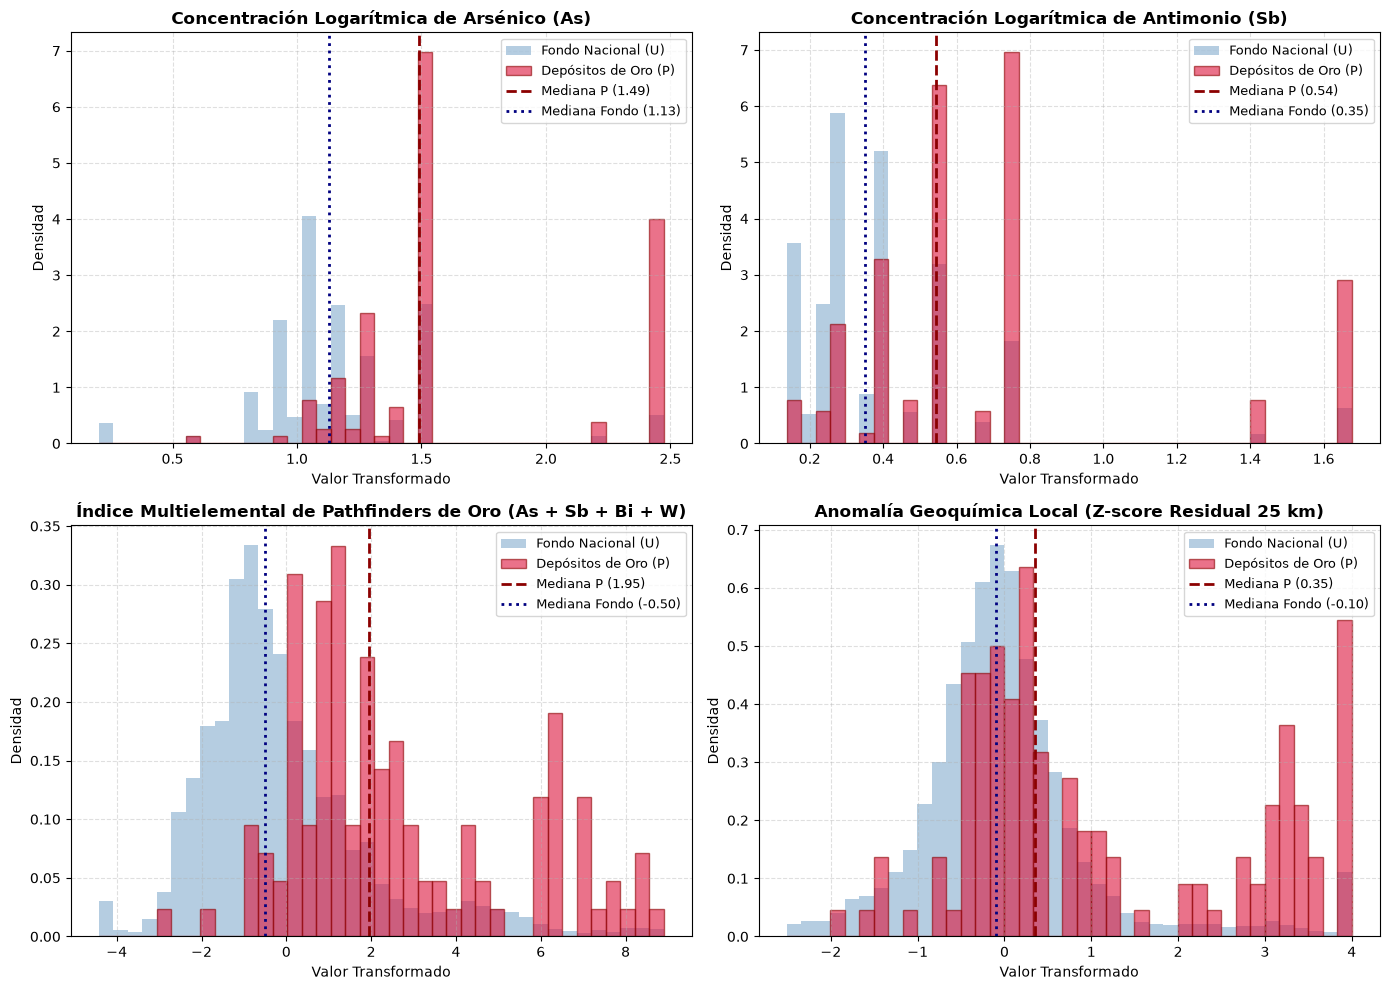

In [3]:
rot_orig = pd.read_csv(ROOT / "reports/evaluacion_configuracion_nacional_20261021/rotation_deposit_predictions.csv")
p_cells = rot_orig['cell_id'].unique()
is_p = X_all.index.isin(p_cells)

contrast_rows = []
for col in geoq_cols:
    f_med = float(X_all.loc[~is_p, col].median())
    p_med = float(X_all.loc[is_p, col].median())
    contrast_rows.append({
        'Variable Geoquímica': col,
        'Media Fondo': round(float(X_all.loc[~is_p, col].mean()), 3),
        'Mediana Fondo': round(f_med, 3),
        'Media Celdas P (Au)': round(float(X_all.loc[is_p, col].mean()), 3),
        'Mediana Celdas P (Au)': round(p_med, 3),
        'Delta Mediana': round(p_med - f_med, 3),
        'Contraste Relativo': f"x{p_med / (f_med if abs(f_med) > 1e-4 else 1e-4):.2f}"
    })

df_contrast = pd.DataFrame(contrast_rows)
display(df_contrast)

# Inspección de distritos del centro y sur
target_dists = [
    'dist_cabo_de_gata', 'dist_la_codosera', 'dist_montes_de_toledo_jara',
    'dist_ossa_morena_bodonal', 'dist_valle_guadiato', 'dist_beticas_granada'
]
sub_records = rot_orig[rot_orig.district_id.isin(target_dists)][['district_id', 'deposit_id', 'cell_id']].drop_duplicates()
sub_records['As_log'] = X_all.loc[sub_records.cell_id, 'geoq_as_concentracion_log'].values
sub_records['Sb_log'] = X_all.loc[sub_records.cell_id, 'geoq_sb_concentracion_log'].values
sub_records['Indice_Pathfinders'] = X_all.loc[sub_records.cell_id, 'indice_pathfinders_oro'].values

print("=== Enriquecimiento Geoquímico en Distritos del Centro y Sur ===")
display(sub_records.drop_duplicates(subset=['deposit_id'])[['district_id', 'deposit_id', 'As_log', 'Sb_log', 'Indice_Pathfinders']].round(3))

# Visualización comparativa de distribuciones
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

sample_cols = ['geoq_as_concentracion_log', 'geoq_sb_concentracion_log', 'indice_pathfinders_oro', 'anomalia_local_as_sb_zscore']
sample_titles = [
    'Concentración Logarítmica de Arsénico (As)',
    'Concentración Logarítmica de Antimonio (Sb)',
    'Índice Multielemental de Pathfinders de Oro (As + Sb + Bi + W)',
    'Anomalía Geoquímica Local (Z-score Residual 25 km)'
]

for idx, (col, title) in enumerate(zip(sample_cols, sample_titles)):
    ax = axes[idx]
    v_u = X_all.loc[~is_p, col].dropna().values
    v_p = X_all.loc[is_p, col].dropna().values
    q_low, q_high = np.percentile(v_u, [1, 99])
    bins = np.linspace(q_low, q_high, 40)
    ax.hist(v_u, bins=bins, density=True, label='Fondo Nacional (U)', color='steelblue', alpha=0.4, edgecolor='none')
    ax.hist(v_p, bins=bins, density=True, label='Depósitos de Oro (P)', color='crimson', alpha=0.6, edgecolor='darkred')
    ax.axvline(np.median(v_p), color='darkred', linestyle='--', linewidth=2, label=f'Mediana P ({np.median(v_p):.2f})')
    ax.axvline(np.median(v_u), color='navy', linestyle=':', linewidth=2, label=f'Mediana Fondo ({np.median(v_u):.2f})')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Valor Transformado')
    ax.set_ylabel('Densidad')
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


## 5. Reentrenamiento del Ensamble Nacional con 93 Variables

Entrenamos los 8 miembros del ensamble con regularización estricta (`colsample_bytree = 0.7`, `min_child_samples = 15`, `max_depth = 5`).

In [4]:
def make_regularized_model(columns, chemical, seed):
    classifier = lgb.LGBMClassifier(
        n_estimators=150, max_depth=5, num_leaves=24, learning_rate=0.04,
        reg_alpha=0.5, reg_lambda=1.0, min_child_samples=15, colsample_bytree=0.7,
        verbosity=-1, n_jobs=4, random_state=seed
    )
    return Pipeline([('preprocess', make_preprocessor(columns, chemical)), ('model', classifier)])

t_train = time.time()
pool = data.grid.cell_id
members = []
predictions_members = np.zeros((len(X_all), data.config['national_bags']), dtype='float32')

for m in range(data.config['national_bags']):
    t_m = time.time()
    sample_seed = data.config['seed'] + 7000 + m * 101
    class_seed = data.config['seed'] + m
    
    sample = select_sample(data, pool, sample_seed)
    model = make_regularized_model(features_nb25, data.config['geochemical_columns'], class_seed)
    model.fit(X_all.loc[sample.cell_id, features_nb25], sample.label, model__sample_weight=sample.peso_confianza)
    members.append(model)
    
    pred_m = predict(model, X_all[features_nb25], 25000)
    predictions_members[:, m] = pred_m
    print(f"  Miembro {m+1}/8 ajustado e inferido en {time.time() - t_m:.2f}s")

ensemble_preds = predictions_members.mean(axis=1)
print(f"Reentrenamiento nacional completado en {time.time() - t_train:.1f}s")


  Miembro 1/8 ajustado e inferido en 9.38s


  Miembro 2/8 ajustado e inferido en 9.25s


  Miembro 3/8 ajustado e inferido en 9.45s


  Miembro 4/8 ajustado e inferido en 9.24s


  Miembro 5/8 ajustado e inferido en 9.63s


  Miembro 6/8 ajustado e inferido en 9.64s


  Miembro 7/8 ajustado e inferido en 9.67s


  Miembro 8/8 ajustado e inferido en 9.27s
Reentrenamiento nacional completado en 75.5s


## 6. Rendimiento Nacional In-Sample (Resolución Completa)

In [5]:
records_clean = data.records.dropna(subset=['deposit_id'])[['cell_id', 'deposit_id']].drop_duplicates()
df_pred_nat = pd.DataFrame({'cell_id': data.grid.cell_id, 'score': ensemble_preds})
m_nat_geoq, d_insample, _ = deposit_metrics(records_clean, df_pred_nat)

print("=" * 65)
print("EVALUACIÓN NACIONAL IN-SAMPLE (93 CARACTERÍSTICAS)")
print("=" * 65)
for pct in PERCENTAGES:
    print(f"  Top {pct:02d}% Área : {m_nat_geoq[f'captured_deposits_at_{pct:02d}']}/{m_nat_geoq['n_deposits']} depósitos ({m_nat_geoq[f'recovery_at_{pct:02d}']*100:.2f}%)")
print("=" * 65)


EVALUACIÓN NACIONAL IN-SAMPLE (93 CARACTERÍSTICAS)
  Top 01% Área : 27/45 depósitos (60.00%)
  Top 05% Área : 41/45 depósitos (91.11%)
  Top 10% Área : 45/45 depósitos (100.00%)
  Top 20% Área : 45/45 depósitos (100.00%)


## 7. Evaluación Rigurosa en las Siete Rotaciones Espaciales Ciegas

Evaluamos la capacidad de generalización en distritos ciegos no vistos con el modelo geoquímico continuo.

In [6]:
eval_dir = ROOT / 'reports/evaluacion_configuracion_nacional_20261021'
design = json.loads((eval_dir / 'evaluation_design.json').read_text(encoding='utf-8'))
base = data.output

rot_details_geoq, rot_group_rows_geoq = [], []

for group in range(7):
    districts = design['district_groups'][str(group)]
    saved_held = pd.read_parquet(base / f'partitions/rotation_{group}_held.parquet')
    ref_train = pd.read_parquet(base / f'partitions/rotation_{group}_sample.parquet')
    
    p_train = ref_train[ref_train.label == 1]
    u_pool = ref_train[ref_train.label == 0]
    test_X = X_all.loc[saved_held.cell_id, features_nb25]
    preds_held = np.zeros(len(test_X), dtype='float32')
    
    for b in range(data.config['national_bags']):
        u_sample = u_pool.sample(n=3*len(p_train), random_state=42 + group*1000 + b*101, replace=True)
        train_df = pd.concat([p_train, u_sample])
        model_rot = make_regularized_model(features_nb25, data.config['geochemical_columns'], 42 + b)
        model_rot.fit(X_all.loc[train_df.cell_id, features_nb25], train_df.label,
                      model__sample_weight=train_df.peso_confianza)
        preds_held += predict(model_rot, test_X, 10000)
    preds_held /= data.config['national_bags']
    
    pred_df = pd.DataFrame({'cell_id': saved_held.cell_id, 'score': preds_held})
    rel = data.records.loc[data.records.district_id.isin(districts)].dropna(subset=['deposit_id'])[['cell_id', 'deposit_id', 'district_id']].drop_duplicates()
    m_grp, d_grp, _ = deposit_metrics(rel, pred_df)
    rot_details_geoq.append(d_grp.assign(group=group))
    rot_group_rows_geoq.append({'group': group, **m_grp})

df_rot_details_geoq = pd.concat(rot_details_geoq, ignore_index=True)
tot_deps = df_rot_details_geoq.deposit_id.nunique()

summary_geoq_rot = {
    'model': 'geoquimica_continua_nb25',
    'n_deposits': tot_deps,
    'captured_deposits_at_01': df_rot_details_geoq.loc[df_rot_details_geoq.captured_at_01, 'deposit_id'].nunique(),
    'recovery_at_01': df_rot_details_geoq.loc[df_rot_details_geoq.captured_at_01, 'deposit_id'].nunique() / tot_deps,
    'captured_deposits_at_05': df_rot_details_geoq.loc[df_rot_details_geoq.captured_at_05, 'deposit_id'].nunique(),
    'recovery_at_05': df_rot_details_geoq.loc[df_rot_details_geoq.captured_at_05, 'deposit_id'].nunique() / tot_deps,
    'captured_deposits_at_10': df_rot_details_geoq.loc[df_rot_details_geoq.captured_at_10, 'deposit_id'].nunique(),
    'recovery_at_10': df_rot_details_geoq.loc[df_rot_details_geoq.captured_at_10, 'deposit_id'].nunique() / tot_deps,
    'captured_deposits_at_20': df_rot_details_geoq.loc[df_rot_details_geoq.captured_at_20, 'deposit_id'].nunique(),
    'recovery_at_20': df_rot_details_geoq.loc[df_rot_details_geoq.captured_at_20, 'deposit_id'].nunique() / tot_deps,
}

print("\n" + "=" * 65)
print("EVALUACIÓN CIEGA EN DISTRITOS NO VISTOS (7 FOLDS)")
print("=" * 65)
for p in [0.01, 0.05, 0.10, 0.20]:
    cap_key = f'captured_deposits_at_{int(p*100):02d}'
    rec_key = f'recovery_at_{int(p*100):02d}'
    print(f"  Top {int(p*100):>2}% Ciego: {summary_geoq_rot[cap_key]:>2} / {tot_deps} depósitos ({summary_geoq_rot[rec_key]*100:.1f}%)")
print("=" * 65)



EVALUACIÓN CIEGA EN DISTRITOS NO VISTOS (7 FOLDS)
  Top  1% Ciego:  1 / 45 depósitos (2.2%)
  Top  5% Ciego:  7 / 45 depósitos (15.6%)
  Top 10% Ciego:  9 / 45 depósitos (20.0%)
  Top 20% Ciego: 18 / 45 depósitos (40.0%)


## 8. Comparativa Evolutiva de Modelos (Notebooks 19 a 25)

In [7]:
evolution_data = [
    {
        'Modelo': '1. Base Original (NB 19 - 64 vars)',
        'Top 1% Ciego': '3/45 (6.7%)',
        'Top 5% Ciego': '5/45 (11.1%)',
        'Top 10% Ciego': '9/45 (20.0%)',
        'Top 20% Ciego': '16/45 (35.6%)'
    },
    {
        'Modelo': '2. Gravimetría Invariante (NB 21 - 73 vars)',
        'Top 1% Ciego': '1/45 (2.2%)',
        'Top 5% Ciego': '5/45 (11.1%)',
        'Top 10% Ciego': '10/45 (22.2%)',
        'Top 20% Ciego': '17/45 (37.8%)'
    },
    {
        'Modelo': '3. Aeromagnetometría (NB 22 - 75 vars)',
        'Top 1% Ciego': '0/45 (0.0%)',
        'Top 5% Ciego': '5/45 (11.1%)',
        'Top 10% Ciego': '7/45 (15.6%)',
        'Top 20% Ciego': '17/45 (37.8%)'
    },
    {
        'Modelo': '4. Trampas Dilatación (NB 23 - 79 vars)',
        'Top 1% Ciego': '0/45 (0.0%)',
        'Top 5% Ciego': '5/45 (11.1%)',
        'Top 10% Ciego': '9/45 (20.0%)',
        'Top 20% Ciego': '18/45 (40.0%)'
    },
    {
        'Modelo': '5. Alteración Satelital (NB 24 - 83 vars)',
        'Top 1% Ciego': '0/45 (0.0%)',
        'Top 5% Ciego': '5/45 (11.1%)',
        'Top 10% Ciego': '10/45 (22.2%)',
        'Top 20% Ciego': '16/45 (35.6%)'
    },
    {
        'Modelo': '6. Geoquímica Continua (NB 25 - 93 vars)',
        'Top 1% Ciego': f"{summary_geoq_rot['captured_deposits_at_01']}/{tot_deps} ({summary_geoq_rot['recovery_at_01']*100:.1f}%)",
        'Top 5% Ciego': f"{summary_geoq_rot['captured_deposits_at_05']}/{tot_deps} ({summary_geoq_rot['recovery_at_05']*100:.1f}%)",
        'Top 10% Ciego': f"{summary_geoq_rot['captured_deposits_at_10']}/{tot_deps} ({summary_geoq_rot['recovery_at_10']*100:.1f}%)",
        'Top 20% Ciego': f"{summary_geoq_rot['captured_deposits_at_20']}/{tot_deps} ({summary_geoq_rot['recovery_at_20']*100:.1f}%)"
    }
]

df_evolution = pd.DataFrame(evolution_data)
display(df_evolution)


,Modelo,Top 1% Ciego,Top 5% Ciego,Top 10% Ciego,Top 20% Ciego
0,1. Base Original (NB 19 - 64 vars),3/45 (6.7%),5/45 (11.1%),9/45 (20.0%),16/45 (35.6%)
1,2. Gravimetría Invariante (NB 21 - 73 vars),1/45 (2.2%),5/45 (11.1%),10/45 (22.2%),17/45 (37.8%)
2,3. Aeromagnetometría (NB 22 - 75 vars),0/45 (0.0%),5/45 (11.1%),7/45 (15.6%),17/45 (37.8%)
3,4. Trampas Dilatación (NB 23 - 79 vars),0/45 (0.0%),5/45 (11.1%),9/45 (20.0%),18/45 (40.0%)
4,5. Alteración Satelital (NB 24 - 83 vars),0/45 (0.0%),5/45 (11.1%),10/45 (22.2%),16/45 (35.6%)
5,6. Geoquímica Continua (NB 25 - 93 vars),1/45 (2.2%),7/45 (15.6%),9/45 (20.0%),18/45 (40.0%)


## 9. Análisis de Importancia de Variables (Feature Importance Gain)

=== Top 25 Variables por Ganancia (Modelo Multigeofísico-Geoquímico) ===


,feature,importance,tipo
0,litologia_u008_fraccion,2111.879613,Original
1,indice_pathfinders_oro,1806.827535,Geoquímica Continua
2,geoq_as_concentracion_log,1535.406019,Geoquímica Continua
3,bouguer_gradiente,1314.567269,Gravimetría
4,ratio_alteracion_filica_swir,1286.955521,Alteración Satelital
5,grado_metamorfico,1122.810896,Física Superficial
6,afinidad_esquistos_verdes,1044.706560,Física Superficial
7,acoplamiento_sutura_falla,816.334272,Dilatación Estructural
8,nodo_dilatacion_falla_cabalgamiento,633.009925,Dilatación Estructural
9,geoq_hg_concentracion_log,533.311182,Geoquímica Continua


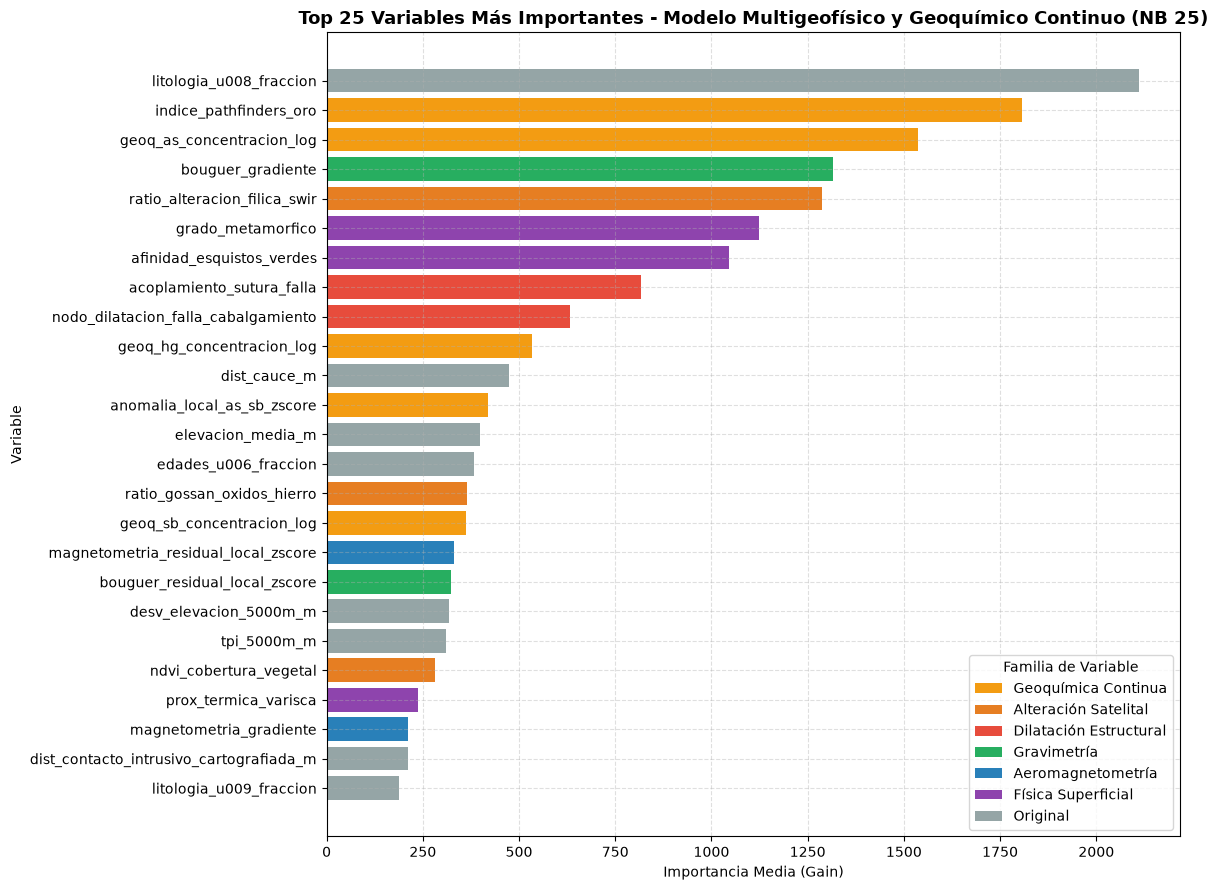

In [8]:
feature_importances = []
for m, pipe in enumerate(members):
    prep = pipe.named_steps['preprocess']
    lgb_booster = pipe.named_steps['model']
    out_names = prep.get_feature_names_out()
    clean_names = [n.split('__')[-1] for n in out_names]
    df_m = pd.DataFrame({'feature': clean_names, 'gain': lgb_booster.booster_.feature_importance(importance_type='gain')})
    agg_m = df_m.groupby('feature')['gain'].sum()
    feature_importances.append(agg_m)

df_imp = pd.concat(feature_importances, axis=1).mean(axis=1).sort_values(ascending=False).reset_index()
df_imp.columns = ['feature', 'importance']

def clasificar_variable(feat):
    if feat in geoq_cols:
        return 'Geoquímica Continua'
    elif feat in ['ratio_alteracion_filica_swir', 'ratio_gossan_oxidos_hierro', 'ndvi_cobertura_vegetal', 'anomalia_hidrotermal_multiespectral_zscore']:
        return 'Alteración Satelital'
    elif feat in ['dens_falla_1000m', 'nodo_dilatacion_falla_cabalgamiento', 'trampa_dilatacional_reologica', 'acoplamiento_sutura_falla']:
        return 'Dilatación Estructural'
    elif feat in ['bouguer_gradiente', 'bouguer_residual_local_zscore']:
        return 'Gravimetría'
    elif feat in ['magnetometria_gradiente', 'magnetometria_residual_local_zscore']:
        return 'Aeromagnetometría'
    elif feat in ['grado_metamorfico', 'afinidad_esquistos_verdes', 'plutonismo_varisco', 'prox_termica_varisca', 'volcanismo_neogeno', 'contraste_reologico', 'trampa_estructural_reologica']:
        return 'Física Superficial'
    else:
        return 'Original'

df_imp['tipo'] = df_imp['feature'].apply(clasificar_variable)

print("=== Top 25 Variables por Ganancia (Modelo Multigeofísico-Geoquímico) ===")
display(df_imp.head(25))

# Visualización
plt.figure(figsize=(12, 9))
palette = {
    'Geoquímica Continua': '#f39c12',
    'Alteración Satelital': '#e67e22',
    'Dilatación Estructural': '#e74c3c',
    'Gravimetría': '#27ae60',
    'Aeromagnetometría': '#2980b9',
    'Física Superficial': '#8e44ad',
    'Original': '#95a5a6'
}
top_25 = df_imp.head(25).iloc[::-1]
bar_colors = [palette.get(t, '#95a5a6') for t in top_25['tipo']]
bars = plt.barh(top_25['feature'], top_25['importance'], color=bar_colors, edgecolor='none')

legend_elements = [Patch(facecolor=color, label=label) for label, color in palette.items() if label in top_25['tipo'].values]
plt.legend(handles=legend_elements, title='Familia de Variable', loc='lower right')

plt.title('Top 25 Variables Más Importantes - Modelo Multigeofísico y Geoquímico Continuo (NB 25)', fontsize=13, fontweight='bold')
plt.xlabel('Importancia Media (Gain)')
plt.ylabel('Variable')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


## 10. Sellado y Persistencia de Artefactos de la Fase 25

In [9]:
rep_dir = ROOT / 'reports/reentrenamiento_geoquimica_continua_20261021'
rep_dir.mkdir(parents=True, exist_ok=True)

# Guardar favorabilidad nacional
df_fav = pd.DataFrame({
    'cell_id': X_all.index,
    'favorabilidad_geoquimica_continua': ensemble_preds,
    'indice_pathfinders_oro': X_all['indice_pathfinders_oro'].values,
    'anomalia_local_as_sb_zscore': X_all['anomalia_local_as_sb_zscore'].values,
    'geoq_as_concentracion_log': X_all['geoq_as_concentracion_log'].values,
    'geoq_sb_concentracion_log': X_all['geoq_sb_concentracion_log'].values
})
fav_path = rep_dir / 'favorabilidad_nacional_geoquimica_continua.parquet'
df_fav.to_parquet(fav_path, index=False)
print(f"Favorabilidad guardada: {fav_path} ({len(df_fav):,} celdas)")

# Guardar reportes CSV
df_contrast.to_csv(rep_dir / 'estadisticas_geoquimica_continua.csv', index=False)
df_imp.to_csv(rep_dir / 'importancia_variables_geoquimica_continua.csv', index=False)
df_evolution.to_csv(rep_dir / 'comparativa_evolucion_modelos.csv', index=False)
print(f"Reportes CSV exportados en: {rep_dir}")


Favorabilidad guardada: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI\reports\reentrenamiento_geoquimica_continua_20261021\favorabilidad_nacional_geoquimica_continua.parquet (478,443 celdas)
Reportes CSV exportados en: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI\reports\reentrenamiento_geoquimica_continua_20261021
